# Random Forest Classifier

Pseudocode steps: load, extract features/labels, split, train, evaluate including CV, feature importances, sweep n_estimators, compare individual trees, save best.

In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from IPython.display import display
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder
import joblib

from schema_utils import detect_feature_columns, build_feature_matrix



In [2]:
# 2. Data Loading - use train/test CSVs
import os
import pandas as pd
DATA_DIR = os.path.join('..','datasets')
TRAIN_PATH = os.path.join(DATA_DIR, 'training_data_train.csv')
TEST_PATH = os.path.join(DATA_DIR, 'training_data_test.csv')
if not os.path.exists(TRAIN_PATH) or not os.path.exists(TEST_PATH):
    raise FileNotFoundError("Missing train/test CSVs in ../datasets: training_data_train.csv and training_data_test.csv")
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)
from schema_utils import detect_feature_columns
schema = detect_feature_columns(df_train)
if not schema['label_col']:
    raise ValueError('No label column detected. Expected one of: label/class/target')
label_col = schema['label_col']
print('Train size:', len(df_train), 'Test size:', len(df_test))
print('Train balance:', df_train[label_col].value_counts(normalize=True))
print('Test balance:', df_test[label_col].value_counts(normalize=True))



Train size: 1421 Test size: 433
Train balance: label
human      0.590429
nothing    0.409571
Name: proportion, dtype: float64
Test balance: label
human      0.505774
nothing    0.494226
Name: proportion, dtype: float64


In [3]:
# 3-4. Features + Split (pre-split train/test, train-only fit)
import numpy as np
from schema_utils import build_feature_matrix
feature_cols = schema['classic_feature_cols']
X_train_all = build_feature_matrix(df_train, feature_cols)
X_test_all = build_feature_matrix(df_test, feature_cols)
# Fill NaNs using training medians
train_medians = np.nanmedian(X_train_all, axis=0)
X_train_all = np.where(np.isnan(X_train_all), train_medians, X_train_all)
X_test_all = np.where(np.isnan(X_test_all), train_medians, X_test_all)
# Labels
y_str_train = df_train[label_col].astype(str).values
y_str_test = df_test[label_col].astype(str).values
from sklearn.preprocessing import LabelEncoder, StandardScaler
le = LabelEncoder()
y_train = le.fit_transform(y_str_train)
y_test = le.transform(y_str_test)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_all)
X_test = scaler.transform(X_test_all)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)
print('Classes:', list(le.classes_))
# Set class weights: cautious on 'human', penalize 'nothing' x2
classes = list(le.classes_)
idx_human = next((i for i, c in enumerate(classes) if c.lower() == 'human'), None)
idx_nothing = next((i for i, c in enumerate(classes) if c.lower() == 'nothing'), None)
if idx_nothing is not None and idx_human is not None:
    rf_class_weight = {idx_human: 1.0, idx_nothing: 2.0}
elif idx_nothing is not None:
    rf_class_weight = {i: (2.0 if i == idx_nothing else 1.0) for i in range(len(classes))}
else:
    rf_class_weight = 'balanced'
print('Using class_weight:', rf_class_weight)



Train shape: (1421, 46) Test shape: (433, 46)
Classes: ['human', 'nothing']
Using class_weight: {0: 1.0, 1: 2.0}


Training accuracy: 1.0
Test accuracy: 0.9561200923787528
5-fold CV mean accuracy: 1.0
Confusion matrix: [[200  19]
 [  0 214]]
              precision    recall  f1-score   support

       human       1.00      0.91      0.95       219
     nothing       0.92      1.00      0.96       214

    accuracy                           0.96       433
   macro avg       0.96      0.96      0.96       433
weighted avg       0.96      0.96      0.96       433



,feature,importance
42,f43,0.170394
29,f30,0.139566
2,f3,0.116440
45,f46,0.110485
28,f29,0.104164
30,f31,0.092965
16,f17,0.061754
41,f42,0.044095
9,f10,0.043810
34,f35,0.034518


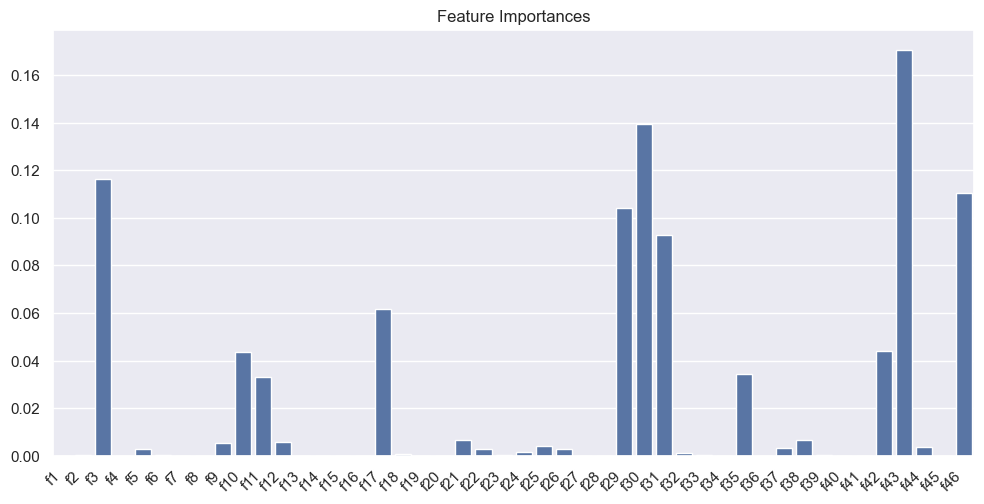

,n_estimators,test_accuracy
0,5,0.942263
1,10,0.960739
2,20,0.956120
3,50,0.963048
4,100,0.974596


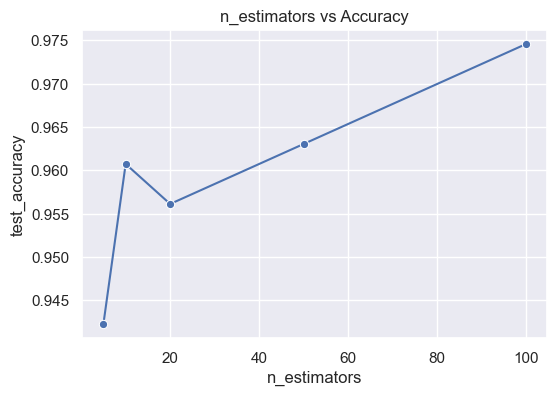

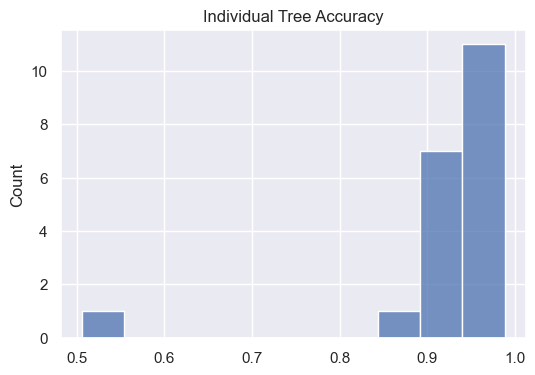

Forest test accuracy: 0.9561200923787528 Individual mean: 0.9235565819861433
Saved best model as random_forest.pkl with n_estimators 100


In [4]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf = RandomForestClassifier(n_estimators=20, max_depth=10, min_samples_leaf=10, random_state=42, n_jobs=-1, class_weight=rf_class_weight)
rf.fit(X_train, y_train)
training_accuracy = rf.score(X_train, y_train)
proba = rf.predict_proba(X_test)
y_pred_max = np.argmax(proba, axis=1)
y_pred_conf = np.max(proba, axis=1)
# Require 70% confidence; fallback to 'nothing' when low confidence
y_pred = np.where(y_pred_conf >= 0.7, y_pred_max, (idx_nothing if idx_nothing is not None else y_pred_max))
test_accuracy = accuracy_score(y_test, y_pred)
cv_scores = cross_val_score(rf, X_train, y_train, cv=5, n_jobs=-1)
print('Training accuracy:', training_accuracy)
print('Test accuracy:', test_accuracy)
print('5-fold CV mean accuracy:', cv_scores.mean())

# y_pred assigned using thresholded predict_proba above
print('Confusion matrix:', confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=list(le.classes_)))

fi = rf.feature_importances_
fi_df = pd.DataFrame({'feature': feature_cols, 'importance': fi}).sort_values('importance', ascending=False)
display(fi_df)
plt.figure(figsize=(10,5))
sns.barplot(x=feature_cols, y=fi)
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.title('Feature Importances'); plt.show()

# Sweep n_estimators
estimators = [5, 10, 20, 50, 100]
rf_results = []
for n in estimators:
    m = RandomForestClassifier(n_estimators=n, max_depth=10, min_samples_leaf=10, random_state=42, n_jobs=-1, class_weight=rf_class_weight)
    m.fit(X_train, y_train)
    proba = m.predict_proba(X_test)
    m_pred_max = np.argmax(proba, axis=1)
    m_pred_conf = np.max(proba, axis=1)
    m_pred = np.where(m_pred_conf >= 0.7, m_pred_max, (idx_nothing if idx_nothing is not None else m_pred_max))
    rf_results.append({'n_estimators': n, 'test_accuracy': accuracy_score(y_test, m_pred)})
rf_df = pd.DataFrame(rf_results)
display(rf_df)
plt.figure(figsize=(6,4)); sns.lineplot(x='n_estimators', y='test_accuracy', data=rf_df, marker='o'); plt.title('n_estimators vs Accuracy'); plt.show()

# Individual trees vs forest
if hasattr(rf, 'estimators_'):
    tree_accs = [est.score(X_test, y_test) for est in rf.estimators_]
    plt.figure(figsize=(6,4)); sns.histplot(tree_accs, bins=10); plt.title('Individual Tree Accuracy'); plt.show()
    print('Forest test accuracy:', test_accuracy, 'Individual mean:', np.mean(tree_accs))

best = max(rf_results, key=lambda r: r['test_accuracy'])
best_model = RandomForestClassifier(n_estimators=best['n_estimators'], max_depth=10, min_samples_leaf=10, random_state=42, n_jobs=-1, class_weight=rf_class_weight)
best_model.fit(np.vstack([X_train,X_test]), np.hstack([y_train,y_test]))
joblib.dump(best_model, os.path.join('..','models','random_forest.pkl'))
print('Saved best model as random_forest.pkl with n_estimators', best['n_estimators'])


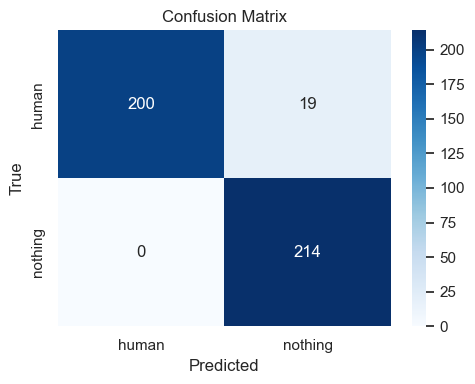

              precision    recall  f1-score   support

       human       1.00      0.91      0.95       219
     nothing       0.92      1.00      0.96       214

    accuracy                           0.96       433
   macro avg       0.96      0.96      0.96       433
weighted avg       0.96      0.96      0.96       433



In [5]:

# Confusion Matrix - Visualize mistakes
from sklearn.metrics import confusion_matrix, classification_report
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(le.classes_), yticklabels=list(le.classes_))
plt.title('Confusion Matrix')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.tight_layout(); plt.show()
print(classification_report(y_test, y_pred, target_names=list(le.classes_)))
